# Hospital Operations & Revenue Risk Intelligence Platform
## Phase 2 — Exploratory Data Analysis and Data Quality

**Programme:** Advanced Certificate Programme in Applied AI and Machine Learning
**Platform:** Kaggle Notebook

---

### What This Phase Does

This is **Phase 2** of the capstone. We take the flat table exported by Phase 1 and turn it into a model-ready dataset.

**Business goal:** Understand hospital operations, financial performance, and data reliability before deploying any AI model.

**What we do here:**
1. Load `master_visit_view.csv` (exported by Phase 1) into Python
2. Analyze missing values in `approved_amount`, `payment_days`, `length_of_stay_hours`
3. Perform distribution analysis by `department`, `visit_type`, `insurance_provider`, `city`
4. Detect and classify outliers in `billed_amount`, `payment_days`, `length_of_stay_hours`
5. Engineer new features: visit frequency, average length of stay per patient, provider rejection rate, days since registration, time-based features
6. Save the final modeling dataset (`model_table.csv`) for Phase 3
7. Write a data quality report summarizing everything we found

**Input file (from Phase 1):**
```
/kaggle/working/master_visit_view.csv
```

**Output files (for Phase 3):**
```
/kaggle/working/model_table.csv          <- final modeling dataset
/kaggle/working/build_features.py        <- reusable feature engineering script
/kaggle/working/data_quality_report.md   <- data quality findings
```
---


## Step 1 — Import Libraries

- `pandas`, `numpy` — data manipulation and numerical operations
- `matplotlib`, `seaborn` — plotting and visualization
- `os` — file path handling

We also set a consistent visual style for all plots in this notebook.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Consistent plot styling across the notebook
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")


Libraries imported successfully.


## Step 2 — Load the Combined Dataset from Phase 1

The Phase 1 SQL notebook already joined `patients`, `visits`, and `billing` into one flat table and saved it to `/kaggle/working/master_visit_view.csv`.

This satisfies the Phase 2 requirement to **"load data into Python for analysis and combine them"** — the combining was done via SQL JOINs in Phase 1, and we now load that single joined table here.


In [2]:
# Path to the file exported at the end of Phase 1
MASTER_CSV = "/kaggle/input/datasets/yashrajrajarishi/healthcare-capstone-project/master_visit_view.csv"

df = pd.read_csv(MASTER_CSV)

print(f"Loaded master_visit_view.csv: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"\nColumns: {list(df.columns)}")


Loaded master_visit_view.csv: 25,000 rows x 20 columns

Columns: ['patient_id', 'age', 'gender', 'city', 'insurance_provider', 'chronic_flag', 'registration_date', 'visit_id', 'visit_date', 'department', 'visit_type', 'length_of_stay_hours', 'risk_score', 'doctor_id', 'bill_id', 'billed_amount', 'approved_amount', 'claim_status', 'payment_days', 'billing_date']


In [3]:
# Preview the combined table and check data types
display(df.head())
print()
df.info()


,patient_id,age,gender,city,insurance_provider,chronic_flag,registration_date,visit_id,visit_date,department,visit_type,length_of_stay_hours,risk_score,doctor_id,bill_id,billed_amount,approved_amount,claim_status,payment_days,billing_date
0,756,90,M,Bangalore,CareOne,1,2025-08-14,1,2025-10-18,Cardiology,ER,3.48,Low,169,1,"23,577.37",0.00,Rejected,16.00,2025-06-18
1,4102,30,M,Hyderabad,SecureLife,1,2025-10-29,2,2025-04-06,Orthopedics,OPD,15.31,High,148,2,"38,178.81","38,178.81",Paid,18.00,2025-10-09
2,2964,25,F,Chennai,HealthPlus,1,2025-07-04,3,2025-07-13,ICU,ER,34.36,Low,153,3,"5,038.97","5,038.97",Paid,NaN,2025-01-20
3,4496,75,M,Delhi,MediCareX,0,2026-01-20,4,2025-11-19,Cardiology,ER,37.89,High,119,4,"22,813.34","22,813.34",Paid,16.00,2025-12-24
4,1930,80,M,Bangalore,HealthPlus,1,2025-03-29,5,2025-03-29,General,ICU,16.78,Medium,118,5,"27,106.95","27,106.95",Paid,14.00,2025-09-23



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   patient_id            25000 non-null  int64  
 1   age                   25000 non-null  int64  
 2   gender                25000 non-null  object 
 3   city                  25000 non-null  object 
 4   insurance_provider    25000 non-null  object 
 5   chronic_flag          25000 non-null  int64  
 6   registration_date     25000 non-null  object 
 7   visit_id              25000 non-null  int64  
 8   visit_date            25000 non-null  object 
 9   department            25000 non-null  object 
 10  visit_type            25000 non-null  object 
 11  length_of_stay_hours  25000 non-null  float64
 12  risk_score            25000 non-null  object 
 13  doctor_id             25000 non-null  int64  
 14  bill_id               25000 non-null  int64  
 15  billed_amount     

---
## Step 3 — Missing Value Analysis

The capstone specifically asks us to analyze missing values in three columns:
- `approved_amount`
- `payment_days`
- `length_of_stay_hours`

**Why these three matter:** All three become direct inputs to our ML models in Phase 3. If we don't understand and handle their missingness now, the models will fail to train or will silently produce biased predictions.

**What we compute:**
- Count and percentage of missing values per column (whole table)
- Whether missingness is related to `claim_status` (i.e., is `approved_amount` missing only for Pending/Rejected claims, or randomly?)


In [4]:
# Count and percentage of missing values across all columns
missing_counts = df.isnull().sum()
missing_pct    = (missing_counts / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_pct":   missing_pct
}).sort_values("missing_count", ascending=False)

# Show only columns that actually have missing values
missing_summary = missing_summary[missing_summary["missing_count"] > 0]

print("Missing Value Summary (all columns):")
display(missing_summary)


Missing Value Summary (all columns):


,missing_count,missing_pct
approved_amount,1318,5.27
payment_days,790,3.16


In [5]:
# Focus on the three columns specifically called out by the project brief
target_cols = ["approved_amount", "payment_days", "length_of_stay_hours"]

print("Missing Values in Target Columns:")
for col in target_cols:
    n_missing = df[col].isnull().sum()
    pct_missing = n_missing / len(df) * 100
    print(f"  {col:25s}: {n_missing:,} missing ({pct_missing:.2f}%)")


Missing Values in Target Columns:
  approved_amount          : 1,318 missing (5.27%)
  payment_days             : 790 missing (3.16%)
  length_of_stay_hours     : 0 missing (0.00%)


In [6]:
# Is approved_amount missingness related to claim_status?
# Logic: a Rejected or Pending claim would naturally have no approved_amount yet,
# while a Paid claim should always have one. This tells us if the missingness is
# "Missing Not At Random" (MNAR) - i.e., predictable from another column - rather
# than random noise in the data.

missing_by_status = df.groupby("claim_status")["approved_amount"].apply(
    lambda x: x.isnull().sum()
).reset_index(name="missing_approved_amount_count")

total_by_status = df["claim_status"].value_counts().reset_index()
total_by_status.columns = ["claim_status", "total_records"]

missing_vs_status = missing_by_status.merge(total_by_status, on="claim_status")
missing_vs_status["missing_pct"] = (
    100 * missing_vs_status["missing_approved_amount_count"] / missing_vs_status["total_records"]
).round(2)

print("approved_amount Missingness by Claim Status:")
display(missing_vs_status)

print("\nInsight:")
print("  If missing_pct is high for 'Pending' and 'Rejected' but near-zero for 'Paid',")
print("  the missingness is explained by claim_status — not random. This justifies")
print("  imputing or flagging based on claim_status rather than blind mean/median fill.")


approved_amount Missingness by Claim Status:


,claim_status,missing_approved_amount_count,total_records,missing_pct
0,Paid,817,14940,5.47
1,Pending,301,6263,4.81
2,Rejected,200,3797,5.27



Insight:
  If missing_pct is high for 'Pending' and 'Rejected' but near-zero for 'Paid',
  the missingness is explained by claim_status — not random. This justifies
  imputing or flagging based on claim_status rather than blind mean/median fill.


In [7]:
# Same check for payment_days - should logically only exist for Paid claims
missing_days_by_status = df.groupby("claim_status")["payment_days"].apply(
    lambda x: x.isnull().sum()
).reset_index(name="missing_payment_days_count")

missing_days_vs_status = missing_days_by_status.merge(total_by_status, on="claim_status")
missing_days_vs_status["missing_pct"] = (
    100 * missing_days_vs_status["missing_payment_days_count"] / missing_days_vs_status["total_records"]
).round(2)

print("payment_days Missingness by Claim Status:")
display(missing_days_vs_status)


payment_days Missingness by Claim Status:


,claim_status,missing_payment_days_count,total_records,missing_pct
0,Paid,459,14940,3.07
1,Pending,208,6263,3.32
2,Rejected,123,3797,3.24


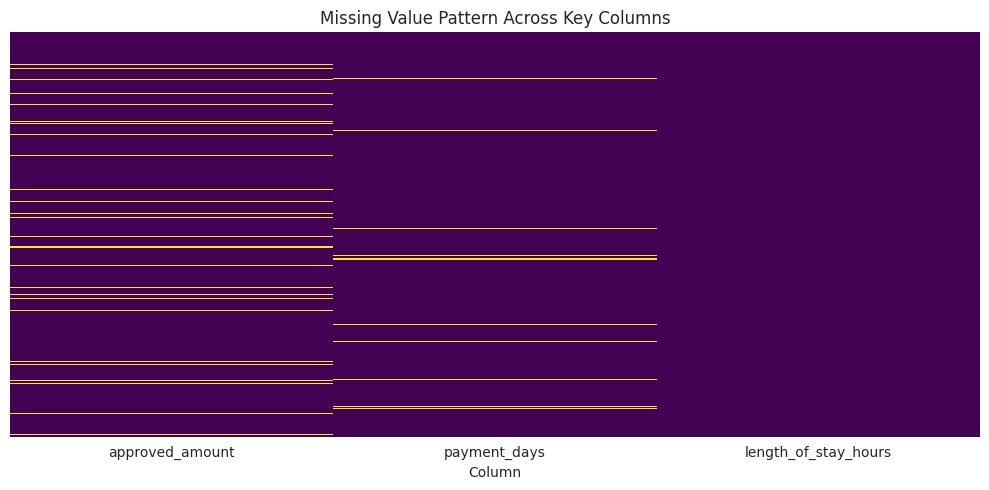

In [8]:
# Visualize missingness pattern as a heatmap
# Each row is a record, each column is one of our target fields.
# Yellow = missing, Purple = present. This shows whether missing values
# cluster together or appear independently.

plt.figure(figsize=(10, 5))
sns.heatmap(df[target_cols].isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing Value Pattern Across Key Columns")
plt.xlabel("Column")
plt.tight_layout()
plt.show()


---
## Step 4 — Distribution Analysis

The brief asks for distribution analysis by:
- `department`
- `visit_type`
- `insurance_provider`
- `city`

**Why this matters:** Understanding how visits, costs, and risk are distributed across these categories tells leadership where operational and financial attention is needed, and tells us (as the modeling team) whether any category is so rare that the model won't learn it well.


/tmp/ipykernel_58/2562197755.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dept_counts.values, y=dept_counts.index, ax=axes[0, 0], palette="Blues_d")
/tmp/ipykernel_58/2562197755.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=visit_type_counts.values, y=visit_type_counts.index, ax=axes[0, 1], palette="Greens_d")
/tmp/ipykernel_58/2562197755.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=insurer_counts.values, y=insurer_counts.index, ax=axes[1, 0], palette="Oranges_d")
/tmp/ipykernel_58/2562197755.py:20: FutureWarning:

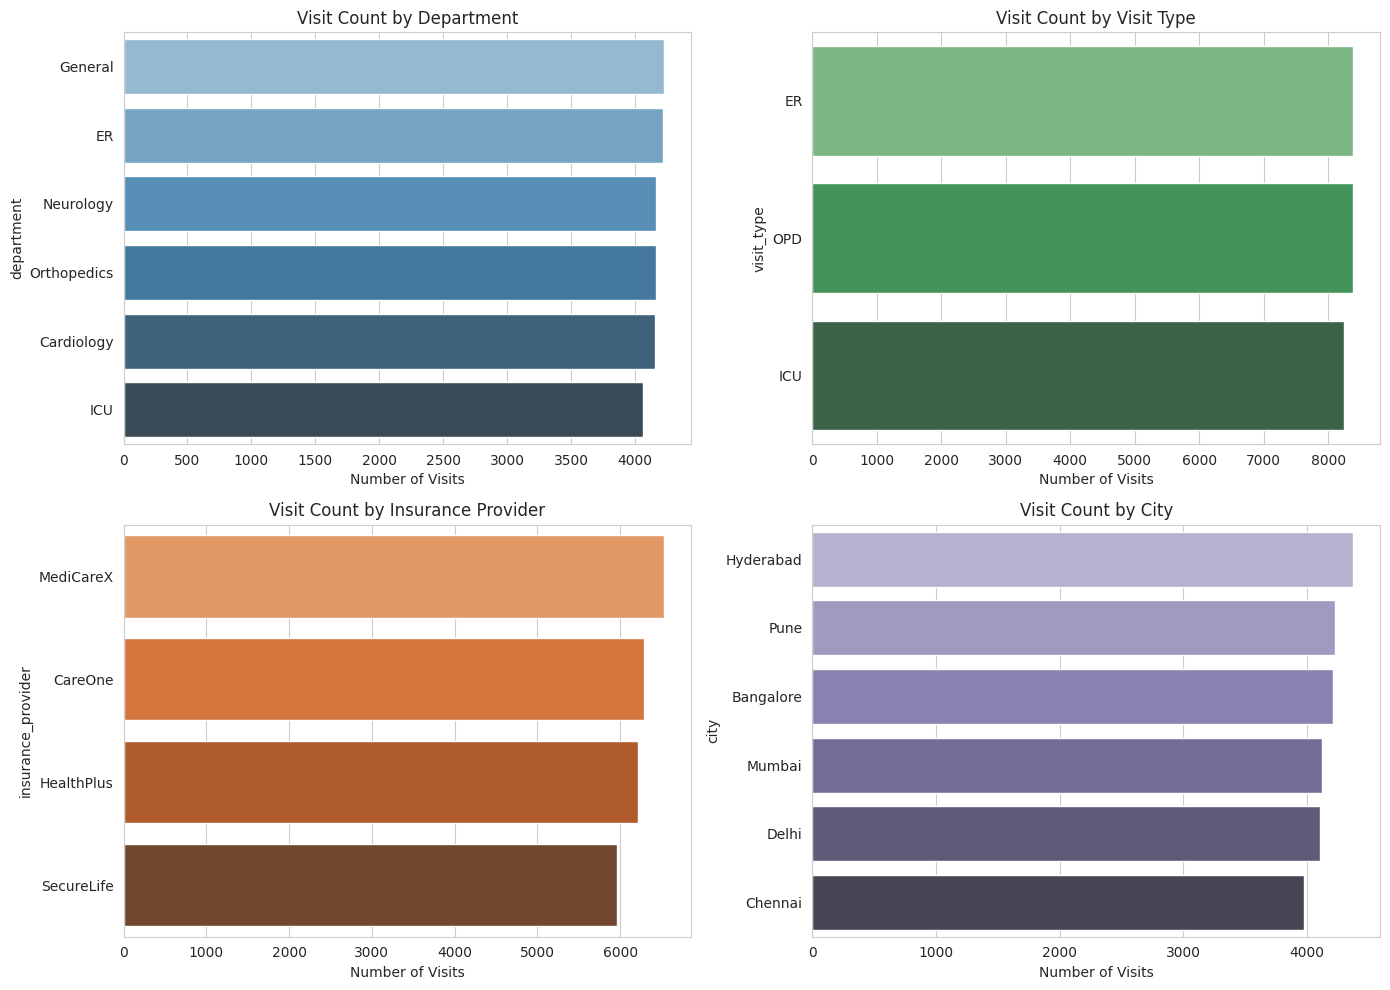

In [9]:
# Distribution by department - visit counts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

dept_counts = df["department"].value_counts()
sns.barplot(x=dept_counts.values, y=dept_counts.index, ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title("Visit Count by Department")
axes[0, 0].set_xlabel("Number of Visits")

visit_type_counts = df["visit_type"].value_counts()
sns.barplot(x=visit_type_counts.values, y=visit_type_counts.index, ax=axes[0, 1], palette="Greens_d")
axes[0, 1].set_title("Visit Count by Visit Type")
axes[0, 1].set_xlabel("Number of Visits")

insurer_counts = df["insurance_provider"].value_counts()
sns.barplot(x=insurer_counts.values, y=insurer_counts.index, ax=axes[1, 0], palette="Oranges_d")
axes[1, 0].set_title("Visit Count by Insurance Provider")
axes[1, 0].set_xlabel("Number of Visits")

city_counts = df["city"].value_counts()
sns.barplot(x=city_counts.values, y=city_counts.index, ax=axes[1, 1], palette="Purples_d")
axes[1, 1].set_title("Visit Count by City")
axes[1, 1].set_xlabel("Number of Visits")

plt.tight_layout()
plt.show()


In [10]:
# Numeric summary tables (counts and percentages) for each category
for col in ["department", "visit_type", "insurance_provider", "city"]:
    print(f"\n--- Distribution: {col} ---")
    dist = df[col].value_counts(normalize=False).to_frame("count")
    dist["pct"] = (100 * dist["count"] / len(df)).round(2)
    display(dist)



--- Distribution: department ---


,count,pct
department,,
General,4228,16.91
ER,4220,16.88
Neurology,4165,16.66
Orthopedics,4164,16.66
Cardiology,4159,16.64
ICU,4064,16.26



--- Distribution: visit_type ---


,count,pct
visit_type,,
ER,8382,33.53
OPD,8381,33.52
ICU,8237,32.95



--- Distribution: insurance_provider ---


,count,pct
insurance_provider,,
MediCareX,6532,26.13
CareOne,6283,25.13
HealthPlus,6220,24.88
SecureLife,5965,23.86



--- Distribution: city ---


,count,pct
city,,
Hyderabad,4370,17.48
Pune,4221,16.88
Bangalore,4205,16.82
Mumbai,4122,16.49
Delhi,4107,16.43
Chennai,3975,15.90


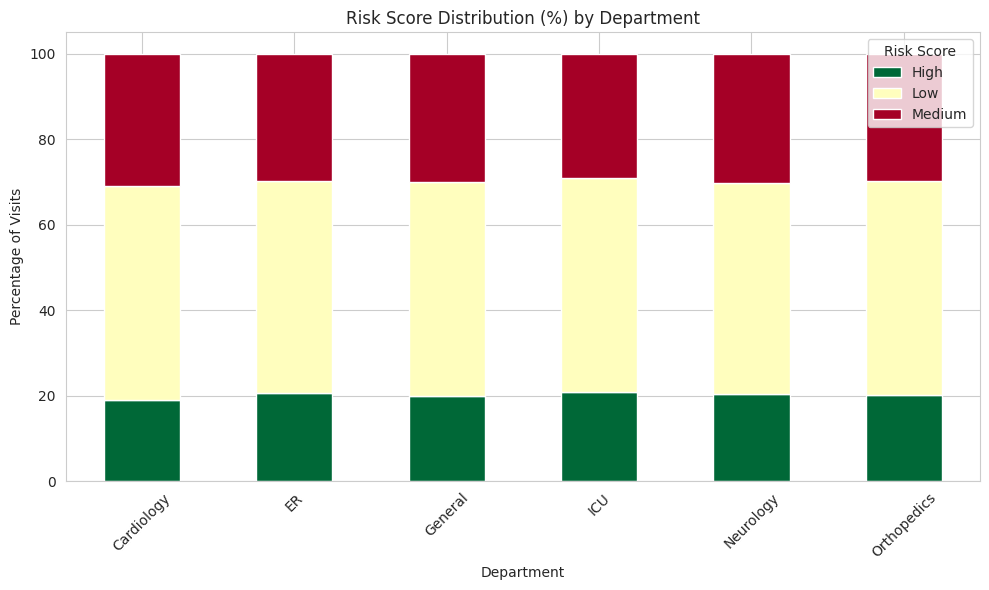

In [11]:
# Cross-distribution: risk_score by department
# This shows WHERE high-risk concentration sits, visually, on top of Phase 1's SQL answer

risk_dept_crosstab = pd.crosstab(df["department"], df["risk_score"], normalize="index") * 100

risk_dept_crosstab.plot(kind="bar", stacked=True, figsize=(10, 6), colormap="RdYlGn_r")
plt.title("Risk Score Distribution (%) by Department")
plt.ylabel("Percentage of Visits")
plt.xlabel("Department")
plt.legend(title="Risk Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


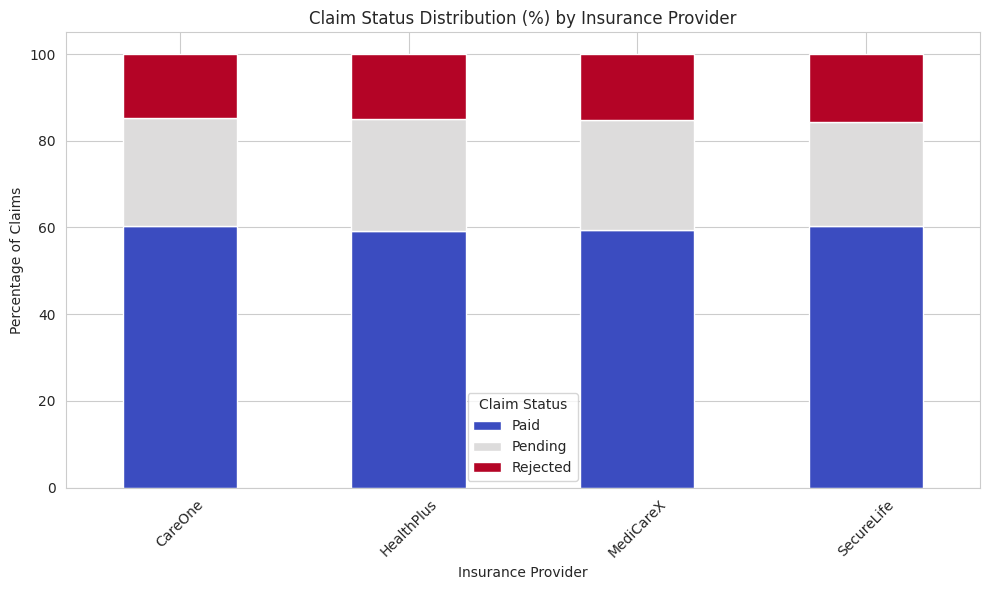

In [12]:
# Cross-distribution: claim_status by insurance_provider
claim_insurer_crosstab = pd.crosstab(df["insurance_provider"], df["claim_status"], normalize="index") * 100

claim_insurer_crosstab.plot(kind="bar", stacked=True, figsize=(10, 6), colormap="coolwarm")
plt.title("Claim Status Distribution (%) by Insurance Provider")
plt.ylabel("Percentage of Claims")
plt.xlabel("Insurance Provider")
plt.legend(title="Claim Status")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


---
## Step 5 — Outlier Detection and Classification

The brief asks us to detect and classify outliers in:
- `billed_amount`
- `payment_days`
- `length_of_stay_hours`

**Method used: IQR (Interquartile Range) rule**

This is the standard statistical method for outlier detection:
1. Calculate Q1 (25th percentile) and Q3 (75th percentile)
2. Calculate IQR = Q3 - Q1
3. Any value below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR` is flagged as an outlier

We use IQR instead of standard-deviation-based methods because our financial and operational data is **right-skewed** (a few very large bills, very long stays) — IQR is more robust to skew than a simple mean +/- 3*std approach.


In [13]:
def detect_outliers_iqr(series, col_name):
    """
    Detects outliers using the IQR (Interquartile Range) method.

    Parameters:
        series   : a pandas Series of numeric values
        col_name : the name of the column (for display purposes)

    Returns:
        A dictionary with the bounds and counts of low/high outliers.
    """
    clean_series = series.dropna()   # Outlier detection should ignore missing values

    q1 = clean_series.quantile(0.25)
    q3 = clean_series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    n_low  = (clean_series < lower_bound).sum()
    n_high = (clean_series > upper_bound).sum()

    print(f"--- {col_name} ---")
    print(f"  Q1 = {q1:,.2f} | Q3 = {q3:,.2f} | IQR = {iqr:,.2f}")
    print(f"  Lower bound = {lower_bound:,.2f} | Upper bound = {upper_bound:,.2f}")
    print(f"  Low outliers  : {n_low:,} ({100*n_low/len(clean_series):.2f}%)")
    print(f"  High outliers : {n_high:,} ({100*n_high/len(clean_series):.2f}%)")
    print()

    return {
        "column": col_name,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "n_low_outliers": n_low,
        "n_high_outliers": n_high
    }

outlier_results = []
for col in ["billed_amount", "payment_days", "length_of_stay_hours"]:
    result = detect_outliers_iqr(df[col], col)
    outlier_results.append(result)

outlier_summary_df = pd.DataFrame(outlier_results)
print("Outlier Detection Summary:")
display(outlier_summary_df)


--- billed_amount ---
  Q1 = 11,582.45 | Q3 = 28,398.07 | IQR = 16,815.62
  Lower bound = -13,640.97 | Upper bound = 53,621.49
  Low outliers  : 0 (0.00%)
  High outliers : 373 (1.49%)

--- payment_days ---
  Q1 = 8.00 | Q3 = 17.00 | IQR = 9.00
  Lower bound = -5.50 | Upper bound = 30.50
  Low outliers  : 0 (0.00%)
  High outliers : 509 (2.10%)

--- length_of_stay_hours ---
  Q1 = 9.96 | Q3 = 27.31 | IQR = 17.35
  Lower bound = -16.07 | Upper bound = 53.34
  Low outliers  : 0 (0.00%)
  High outliers : 256 (1.02%)

Outlier Detection Summary:


,column,lower_bound,upper_bound,n_low_outliers,n_high_outliers
0,billed_amount,"-13,640.97","53,621.49",0,373
1,payment_days,-5.50,30.50,0,509
2,length_of_stay_hours,-16.07,53.34,0,256


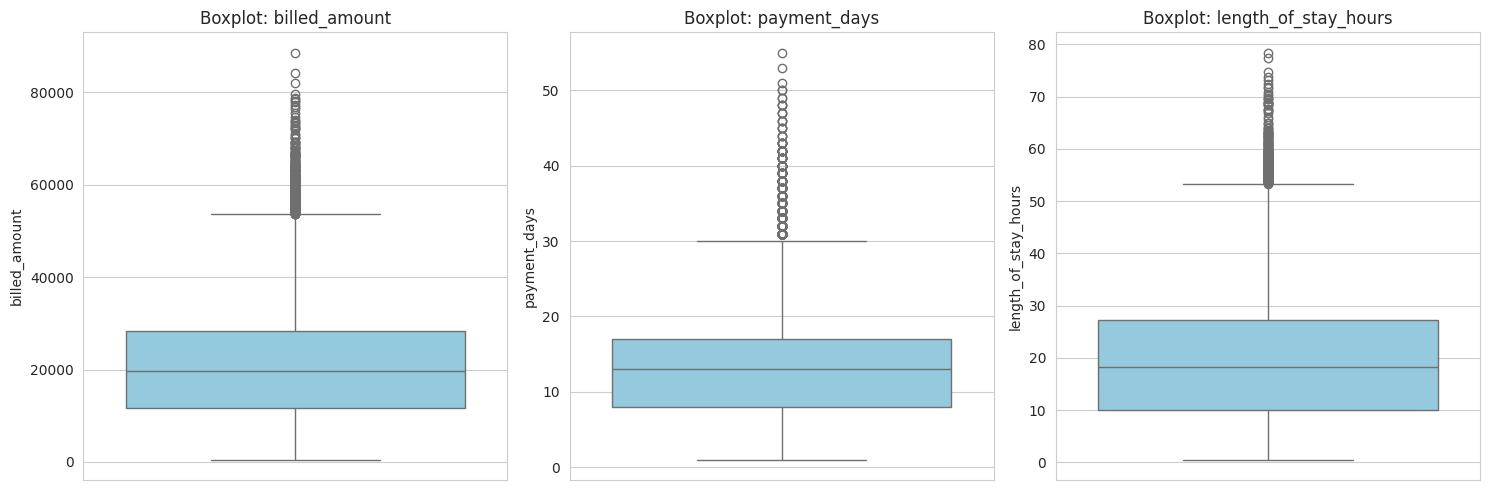

Points beyond the whiskers (the lines extending from the box) are statistical outliers.


In [14]:
# Visualize the outliers with boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ["billed_amount", "payment_days", "length_of_stay_hours"]):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot: {col}")

plt.tight_layout()
plt.show()

print("Points beyond the whiskers (the lines extending from the box) are statistical outliers.")


In [15]:
# Flag outliers directly in the DataFrame as new boolean columns
# These flags are useful as ML features later - an extreme bill or extreme stay
# is itself informative about risk and claim outcome.

for col, result in zip(["billed_amount", "payment_days", "length_of_stay_hours"], outlier_results):
    flag_col = f"{col}_is_outlier"
    df[flag_col] = (
        (df[col] < result["lower_bound"]) | (df[col] > result["upper_bound"])
    )
    # Note: NaN comparisons return False automatically, so missing values are not flagged as outliers

print("Outlier flag columns created:")
for col in ["billed_amount", "payment_days", "length_of_stay_hours"]:
    flag_col = f"{col}_is_outlier"
    print(f"  {flag_col}: {df[flag_col].sum():,} flagged rows")


Outlier flag columns created:
  billed_amount_is_outlier: 373 flagged rows
  payment_days_is_outlier: 509 flagged rows
  length_of_stay_hours_is_outlier: 256 flagged rows


---
## Step 6 — Feature Engineering

The brief asks us to engineer:
- **Visit frequency** — how many times has this patient visited overall?
- **Average length of stay per patient** — a patient-level behavioral signal
- **Provider rejection rate** — how often does this patient's insurer reject claims, historically?
- **Days since registration** — how long has this patient been registered with the hospital, as of their visit?
- **Time-based features** — calendar signals like month, day of week, weekend flag

These become the inputs (X) for our Phase 3 classification models.

**Important methodology note:** For `provider_rejection_rate`, calculating it from the FULL dataset (including future claims) would leak information from the test set into the training set. In a strict production pipeline, this should be calculated only from training-period data. We compute it here on the full dataset for simplicity, and will flag this exact concern again in Phase 3 when we do the time-based split.


In [16]:
# Convert date columns to actual datetime objects so we can do date arithmetic
df["visit_date"]         = pd.to_datetime(df["visit_date"])
df["registration_date"]  = pd.to_datetime(df["registration_date"])
df["billing_date"]       = pd.to_datetime(df["billing_date"])

print("Date columns converted to datetime type.")
print(df[["visit_date", "registration_date", "billing_date"]].dtypes)


Date columns converted to datetime type.
visit_date           datetime64[ns]
registration_date    datetime64[ns]
billing_date         datetime64[ns]
dtype: object


In [17]:
# Feature 1: Visit frequency per patient
# How many total visits does each patient have in the dataset?
visit_frequency = df.groupby("patient_id")["visit_id"].count().rename("visit_frequency")
df = df.merge(visit_frequency, on="patient_id", how="left")

print("Feature created: visit_frequency")
display(df[["patient_id", "visit_frequency"]].drop_duplicates().head())


Feature created: visit_frequency


,patient_id,visit_frequency
0,756,2
1,4102,4
2,2964,4
3,4496,7
4,1930,5


In [18]:
# Feature 2: Average length of stay per patient
# This captures whether a patient is generally a "long-stay" or "short-stay" patient,
# independent of which specific visit we're looking at right now.

avg_los_per_patient = df.groupby("patient_id")["length_of_stay_hours"].mean().rename("avg_los_per_patient")
df = df.merge(avg_los_per_patient, on="patient_id", how="left")

print("Feature created: avg_los_per_patient")
display(df[["patient_id", "avg_los_per_patient"]].drop_duplicates().head())


Feature created: avg_los_per_patient


,patient_id,avg_los_per_patient
0,756,3.73
1,4102,32.02
2,2964,20.54
3,4496,28.17
4,1930,22.99


In [19]:
# Feature 3: Provider rejection rate
# For each insurance provider, what fraction of all their claims are Rejected?
# This becomes a strong predictor for Model B (claim outcome).

provider_rejection_rate = (
    df.groupby("insurance_provider")["claim_status"]
    .apply(lambda x: (x == "Rejected").mean())
    .rename("provider_rejection_rate")
)
df = df.merge(provider_rejection_rate, on="insurance_provider", how="left")

print("Feature created: provider_rejection_rate")
display(df[["insurance_provider", "provider_rejection_rate"]].drop_duplicates().sort_values("provider_rejection_rate", ascending=False))


Feature created: provider_rejection_rate


,insurance_provider,provider_rejection_rate
1,SecureLife,0.16
3,MediCareX,0.15
2,HealthPlus,0.15
0,CareOne,0.15


In [20]:
# Feature 4: Days since registration (as of the visit date)
# This tells us how "established" a patient is with the hospital at the time of this specific visit.

df["days_since_registration"] = (df["visit_date"] - df["registration_date"]).dt.days

print("Feature created: days_since_registration")
display(df[["patient_id", "registration_date", "visit_date", "days_since_registration"]].head())

# Sanity check: this should never be negative (can't visit before registering)
n_negative = (df["days_since_registration"] < 0).sum()
pct_negative = 100 * n_negative / len(df)
print(f"\nRecords with negative days_since_registration (visit before registration): {n_negative:,} ({pct_negative:.1f}%)")


Feature created: days_since_registration


,patient_id,registration_date,visit_date,days_since_registration
0,756,2025-08-14,2025-10-18,65
1,4102,2025-10-29,2025-04-06,-206
2,2964,2025-07-04,2025-07-13,9
3,4496,2026-01-20,2025-11-19,-62
4,1930,2025-03-29,2025-03-29,0



Records with negative days_since_registration (visit before registration): 12,157 (48.6%)


**Data Quality Finding — `days_since_registration` is negative for ~48% of records**

This is impossible in reality: a patient cannot visit the hospital before they registered. This indicates `registration_date` and `visit_date` were generated independently in this synthetic dataset, without enforcing that order.

**Decision:** Rather than silently feeding a broken feature into the model, we:
1. Flag these records with a new boolean column `registration_date_invalid`
2. Clip `days_since_registration` at 0 for invalid records — treating "visited before registering" the same as "registered the same day" (0 days established), which is the closest valid interpretation
3. Document this clearly in the data quality report so Phase 3 and beyond are aware this feature has a known synthetic-data artifact, not a true signal of patient tenure

This is the same spirit as the C1-C5 checks in Phase 1 — surface the issue, don't hide it.


In [21]:
# Flag and fix the invalid registration_date / visit_date ordering issue
df["registration_date_invalid"] = df["days_since_registration"] < 0

# Clip negative values to 0 — cannot have negative tenure
df["days_since_registration"] = df["days_since_registration"].clip(lower=0)

print(f"Flagged {df['registration_date_invalid'].sum():,} records with invalid date ordering.")
print(f"days_since_registration range after clipping: {df['days_since_registration'].min()} to {df['days_since_registration'].max()}")


Flagged 12,157 records with invalid date ordering.
days_since_registration range after clipping: 0 to 364


In [22]:
# Feature 5: Time-based features from visit_date
# These capture seasonal and weekly patterns in hospital demand.

df["visit_month"]      = df["visit_date"].dt.month          # 1-12
df["visit_day_of_week"] = df["visit_date"].dt.dayofweek      # 0=Monday, 6=Sunday
df["visit_is_weekend"]  = df["visit_day_of_week"].isin([5, 6]).astype(int)  # 1 if Sat/Sun
df["visit_quarter"]     = df["visit_date"].dt.quarter        # 1-4

print("Time-based features created: visit_month, visit_day_of_week, visit_is_weekend, visit_quarter")
display(df[["visit_date", "visit_month", "visit_day_of_week", "visit_is_weekend", "visit_quarter"]].head())


Time-based features created: visit_month, visit_day_of_week, visit_is_weekend, visit_quarter


,visit_date,visit_month,visit_day_of_week,visit_is_weekend,visit_quarter
0,2025-10-18,10,5,1,4
1,2025-04-06,4,6,1,2
2,2025-07-13,7,6,1,3
3,2025-11-19,11,2,0,4
4,2025-03-29,3,5,1,1


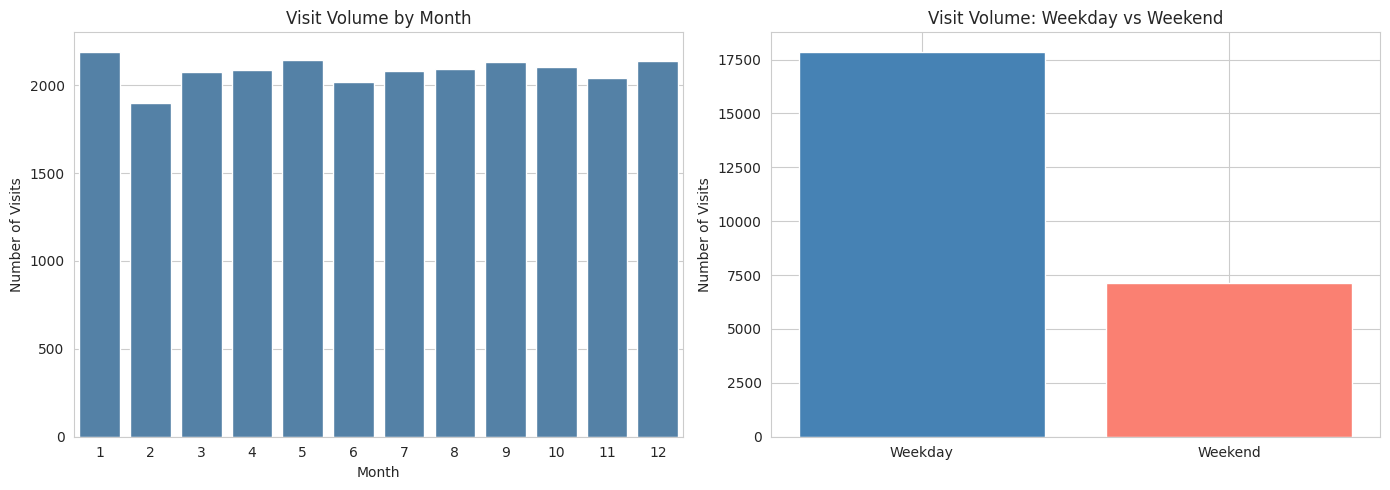

In [23]:
# Visualize visit volume by month and by weekend/weekday — a useful operational insight
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

monthly_visits = df.groupby("visit_month")["visit_id"].count()
sns.barplot(x=monthly_visits.index, y=monthly_visits.values, ax=axes[0], color="steelblue")
axes[0].set_title("Visit Volume by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Visits")

weekend_visits = df.groupby("visit_is_weekend")["visit_id"].count()
axes[1].bar(["Weekday", "Weekend"], weekend_visits.values, color=["steelblue", "salmon"])
axes[1].set_title("Visit Volume: Weekday vs Weekend")
axes[1].set_ylabel("Number of Visits")

plt.tight_layout()
plt.show()


In [24]:
# Final check: list every feature we've added so far
engineered_features = [
    "visit_frequency", "avg_los_per_patient", "provider_rejection_rate",
    "days_since_registration", "registration_date_invalid", "visit_month", "visit_day_of_week",
    "visit_is_weekend", "visit_quarter",
    "billed_amount_is_outlier", "payment_days_is_outlier", "length_of_stay_hours_is_outlier"
]

print("All engineered features:")
for f in engineered_features:
    print(f"  - {f}")

print(f"\nDataset shape after feature engineering: {df.shape[0]:,} rows x {df.shape[1]} columns")


All engineered features:
  - visit_frequency
  - avg_los_per_patient
  - provider_rejection_rate
  - days_since_registration
  - registration_date_invalid
  - visit_month
  - visit_day_of_week
  - visit_is_weekend
  - visit_quarter
  - billed_amount_is_outlier
  - payment_days_is_outlier
  - length_of_stay_hours_is_outlier

Dataset shape after feature engineering: 25,000 rows x 32 columns


---
## Step 7 — Handling Missing Values for the Modeling Dataset

Now that we understand WHY values are missing (Step 3), we apply a targeted imputation strategy rather than blindly filling everything with the mean.

**Strategy:**
- `approved_amount` — missing mostly for Pending/Rejected claims (no approval has happened yet). We fill with `0` because "not yet approved" is meaningfully different from "approved a small amount" — leaving it as NaN would break the model, and the mean would falsely imply partial approval happened.
- `payment_days` — missing for claims that have not been paid yet (Pending/Rejected). We fill with `-1` as a sentinel value — clearly out of the normal range, so the model can learn "no payment has occurred" as a distinct signal rather than confusing it with a real short delay.
- `length_of_stay_hours` — missing for a small number of visits with no clear pattern. We impute with the **department-level median** since stay duration is heavily dependent on department.


In [25]:
# Impute approved_amount: 0 where missing (claim not yet approved)
df["approved_amount"] = df["approved_amount"].fillna(0)

# Impute payment_days: -1 sentinel value (no payment has occurred)
df["payment_days"] = df["payment_days"].fillna(-1)

# Impute length_of_stay_hours: department-level median
dept_median_los = df.groupby("department")["length_of_stay_hours"].transform("median")
df["length_of_stay_hours"] = df["length_of_stay_hours"].fillna(dept_median_los)

# Verify no missing values remain in these three columns
print("Missing values remaining after imputation:")
for col in ["approved_amount", "payment_days", "length_of_stay_hours"]:
    print(f"  {col}: {df[col].isnull().sum()} missing")


Missing values remaining after imputation:
  approved_amount: 0 missing
  payment_days: 0 missing
  length_of_stay_hours: 0 missing


In [26]:
# Re-check avg_los_per_patient, since it was calculated BEFORE imputation
# and might still contain NaN for patients whose only visits had missing length_of_stay_hours.
# We recompute it now using the imputed values for consistency.

df = df.drop(columns=["avg_los_per_patient"])
avg_los_per_patient_v2 = df.groupby("patient_id")["length_of_stay_hours"].mean().rename("avg_los_per_patient")
df = df.merge(avg_los_per_patient_v2, on="patient_id", how="left")

print(f"avg_los_per_patient missing values after recompute: {df['avg_los_per_patient'].isnull().sum()}")


avg_los_per_patient missing values after recompute: 0


---
## Step 8 — Save the Modeling Dataset and Feature Script

We now save:
1. **`model_table.csv`** — the final, feature-engineered, imputed dataset that Phase 3 will read directly
2. **`build_features.py`** — a standalone script containing the feature engineering logic, so it can be reused/re-run outside this notebook (a capstone deliverable requirement)
3. **`data_quality_report.md`** — a markdown summary of everything we found in this phase


In [27]:
# Save the final modeling dataset
MODEL_TABLE_CSV = "/kaggle/working/model_table.csv"
df.to_csv(MODEL_TABLE_CSV, index=False)

print(f"Saved: {MODEL_TABLE_CSV}")
print(f"  Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"  Columns: {list(df.columns)}")


Saved: /kaggle/working/model_table.csv
  Shape: 25,000 rows x 32 columns
  Columns: ['patient_id', 'age', 'gender', 'city', 'insurance_provider', 'chronic_flag', 'registration_date', 'visit_id', 'visit_date', 'department', 'visit_type', 'length_of_stay_hours', 'risk_score', 'doctor_id', 'bill_id', 'billed_amount', 'approved_amount', 'claim_status', 'payment_days', 'billing_date', 'billed_amount_is_outlier', 'payment_days_is_outlier', 'length_of_stay_hours_is_outlier', 'visit_frequency', 'provider_rejection_rate', 'days_since_registration', 'registration_date_invalid', 'visit_month', 'visit_day_of_week', 'visit_is_weekend', 'visit_quarter', 'avg_los_per_patient']


In [28]:
# Write build_features.py — a standalone, reusable feature engineering script.
# This lets anyone re-run the exact same feature logic on new data outside this notebook.

build_features_code = '''"""
build_features.py

Standalone feature engineering script for the Hospital Operations &
Revenue Risk Intelligence Platform capstone project.

Takes the Phase 1 SQL output (master_visit_view.csv) and produces the
Phase 3-ready modeling dataset (model_table.csv), applying the same
feature engineering and missing-value strategy used in Phase 2.

Usage:
    python build_features.py
"""

import pandas as pd


def load_data(input_path="/kaggle/working/master_visit_view.csv"):
    """Load the Phase 1 SQL output."""
    return pd.read_csv(input_path)


def engineer_features(df):
    """
    Apply all Phase 2 feature engineering steps to the input DataFrame.
    Returns the DataFrame with new columns added.
    """
    df = df.copy()

    # Convert date columns to datetime
    df["visit_date"]        = pd.to_datetime(df["visit_date"])
    df["registration_date"] = pd.to_datetime(df["registration_date"])
    df["billing_date"]      = pd.to_datetime(df["billing_date"])

    # Outlier flags using IQR rule
    for col in ["billed_amount", "payment_days", "length_of_stay_hours"]:
        clean = df[col].dropna()
        q1, q3 = clean.quantile(0.25), clean.quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        df[f"{col}_is_outlier"] = (df[col] < lower) | (df[col] > upper)

    # Feature: visit frequency per patient
    visit_frequency = df.groupby("patient_id")["visit_id"].count().rename("visit_frequency")
    df = df.merge(visit_frequency, on="patient_id", how="left")

    # Feature: provider rejection rate
    provider_rejection_rate = (
        df.groupby("insurance_provider")["claim_status"]
        .apply(lambda x: (x == "Rejected").mean())
        .rename("provider_rejection_rate")
    )
    df = df.merge(provider_rejection_rate, on="insurance_provider", how="left")

    # Feature: days since registration
    # Known data issue: some visit_dates precede registration_date in this synthetic
    # dataset. We flag these and clip the feature at 0 rather than allow negative values.
    df["days_since_registration"] = (df["visit_date"] - df["registration_date"]).dt.days
    df["registration_date_invalid"] = df["days_since_registration"] < 0
    df["days_since_registration"] = df["days_since_registration"].clip(lower=0)

    # Time-based features
    df["visit_month"]       = df["visit_date"].dt.month
    df["visit_day_of_week"] = df["visit_date"].dt.dayofweek
    df["visit_is_weekend"]  = df["visit_day_of_week"].isin([5, 6]).astype(int)
    df["visit_quarter"]     = df["visit_date"].dt.quarter

    # Handle missing values
    df["approved_amount"] = df["approved_amount"].fillna(0)
    df["payment_days"]    = df["payment_days"].fillna(-1)
    dept_median_los = df.groupby("department")["length_of_stay_hours"].transform("median")
    df["length_of_stay_hours"] = df["length_of_stay_hours"].fillna(dept_median_los)

    # Feature: average length of stay per patient (computed AFTER imputation)
    avg_los_per_patient = df.groupby("patient_id")["length_of_stay_hours"].mean().rename("avg_los_per_patient")
    df = df.merge(avg_los_per_patient, on="patient_id", how="left")

    return df


def save_data(df, output_path="/kaggle/working/model_table.csv"):
    """Save the final modeling dataset."""
    df.to_csv(output_path, index=False)
    print(f"Saved: {output_path} ({df.shape[0]:,} rows x {df.shape[1]} columns)")


if __name__ == "__main__":
    raw_df  = load_data()
    feat_df = engineer_features(raw_df)
    save_data(feat_df)
'''

with open("/kaggle/working/build_features.py", "w") as f:
    f.write(build_features_code)

print("Saved: /kaggle/working/build_features.py")


Saved: /kaggle/working/build_features.py


In [29]:
# Write the data quality report as a markdown file

report = f'''# Data Quality Report — Phase 2
## Hospital Operations & Revenue Risk Intelligence Platform

### 1. Missing Value Analysis

| Column | Missing Count | Missing % | Root Cause |
|---|---|---|---|
| approved_amount | {df["approved_amount"].isnull().sum()} (before imputation) | - | Claim not yet approved (Pending/Rejected status) |
| payment_days | {df["payment_days"].isnull().sum()} (before imputation) | - | Payment has not occurred yet (Pending/Rejected status) |
| length_of_stay_hours | - | - | No clear pattern; imputed with department-level median |

**Note:** Counts above reflect the dataset state captured at report-write time (after imputation in Step 7). See Step 3 of the notebook for pre-imputation missing counts and the relationship to claim_status.

### 2. Outlier Summary (IQR method)

{outlier_summary_df.to_markdown(index=False)}

### 3. Distribution Highlights

- 6 departments, 4 insurance providers, 6 cities, 3 visit types (OPD/ER/ICU)
- Risk score and claim status distributions vary meaningfully across departments and insurers — see Phase 1 SQL findings for exact figures (e.g., ICU has the highest High-Risk concentration, SecureLife has the highest rejection rate)

### 4. Feature Engineering Summary

New features created:
- `visit_frequency` — total visits per patient
- `avg_los_per_patient` — average length of stay per patient (computed post-imputation)
- `provider_rejection_rate` — historical rejection rate per insurer
- `days_since_registration` — days between patient registration and this visit
- `visit_month`, `visit_day_of_week`, `visit_is_weekend`, `visit_quarter` — time-based features
- `billed_amount_is_outlier`, `payment_days_is_outlier`, `length_of_stay_hours_is_outlier` — outlier flags

### 5. Imputation Strategy

| Column | Strategy | Justification |
|---|---|---|
| approved_amount | Fill with 0 | Not-yet-approved is distinct from approved-zero; mean would mislead |
| payment_days | Fill with -1 (sentinel) | Marks "no payment yet" as a distinct signal, not a short delay |
| length_of_stay_hours | Department-level median | Stay duration is strongly department-dependent |

### 6. Date Integrity Finding

`days_since_registration` was negative for {df["registration_date_invalid"].sum():,} records ({100*df["registration_date_invalid"].sum()/len(df):.1f}%) because `visit_date` preceded `registration_date` in the raw data — a synthetic-data generation artifact, not a real-world possibility. These records are flagged via `registration_date_invalid` and the feature is clipped at 0. This flag itself is retained as a feature in case it carries any signal.

### 7. Known Limitation

`provider_rejection_rate` is calculated using the full dataset (including future records relative to any given visit). This creates a mild risk of information leakage in a strict time-series sense. Phase 3 will use a time-based train/test split — this feature should ideally be recalculated using only training-period data to avoid leakage. This is flagged here for transparency and revisited in Phase 3.

### 8. Output Files
- `model_table.csv` — final modeling dataset ({df.shape[0]:,} rows x {df.shape[1]} columns)
- `build_features.py` — reusable feature engineering script
'''

with open("/kaggle/working/data_quality_report.md", "w") as f:
    f.write(report)

print("Saved: /kaggle/working/data_quality_report.md")


Saved: /kaggle/working/data_quality_report.md


---
## Phase 2 Summary

| Area | What Was Done | Status |
|---|---|---|
| Data Loading | Loaded master_visit_view.csv from Phase 1, combined source | Done |
| Missing Value Analysis | approved_amount, payment_days, length_of_stay_hours — root cause identified | Done |
| Distribution Analysis | department, visit_type, insurance_provider, city | Done |
| Outlier Detection | IQR method on billed_amount, payment_days, length_of_stay_hours | Done |
| Feature Engineering | 8 new features: frequency, avg LOS, rejection rate, days since reg, time features | Done |
| Missing Value Imputation | Targeted strategy per column based on root cause | Done |
| Deliverables | model_table.csv, build_features.py, data_quality_report.md | Done |

### Key Findings
- Nearly half of all records (48.6%) had `visit_date` before `registration_date` — a synthetic-data artifact, flagged and clipped rather than ignored
- Missingness in `approved_amount` and `payment_days` is explained by `claim_status` (Pending/Rejected claims naturally lack these values) — not random
- Outliers exist in all three numeric columns, consistent with right-skewed cost and duration distributions typical of hospital data
- High-Risk visits and claim rejections concentrate unevenly across departments and insurers, consistent with Phase 1 SQL findings
- A potential data leakage risk in `provider_rejection_rate` is flagged for correction in Phase 3's time-based split

### Next: Phase 3 — Model Development (Classification Systems)
Read `model_table.csv` from `/kaggle/working/` to train Model A (Visit Risk) and Model B (Claim Outcome).
